# M8 analysis on the new data: check notebook

## Plain-language guide

**What this module is for.** The study asks one question: when a newcomer on English Wikipedia asks their
assigned mentor a question and gets a reply, are they more likely to keep editing? M8 is the step that answers
it. All earlier modules (M1 to M7) collect and clean the data; M8 turns that data into the effect sizes, the
confidence intervals and the extra checks reported in the paper.

**What goes in.** One file built by M7: `data/analytic/psm_dataset_legacy_layout.npz`. It has one row per
newcomer. The main analysis sample is the 33,518 newcomers in `in_sample` whose 14-day window ends before the
data cutoff (25,760 of them got a reply). For each newcomer it holds: whether they got a
reply (the "treatment"), 164 background facts measured before the reply (edit history, account age, length and
tone of the question, question type, text embedding summaries, month), and the outcomes (for example, did they
make at least one edit to an article in the 14 days after the reply).

**What it does, step by step.**
1. **Propensity score.** Newcomers who get replies are not a random group: for example, they ask clearer,
   more substantive questions. So M8 first predicts, for each newcomer, the chance of getting a reply from their
   164 background facts. This predicted chance is the propensity score. Each person's score comes from a model
   that did not see that person (5-fold cross-fitting: split people into 5 parts, predict each part with a model
   trained on the other 4).
2. **Strata.** Sort everyone by that score and cut them into 10 equal-sized groups (strata). Inside one group,
   everyone had about the same chance of a reply. So we compare each replied newcomer with similar newcomers in
   the same group who did not get a reply.
3. **ATT** (average effect on the treated). In each group, take the share of replied newcomers who kept editing
   minus the share of non-replied newcomers who kept editing. Average these 10 differences, giving more weight to
   groups with more replied newcomers. The result answers: "for the newcomers who did get a reply, how much did
   the reply raise their chance of editing?"
4. **Bootstrap** (for the uncertainty range). Redraw the sample of newcomers at random with replacement 500
   times, recompute the ATT each time, and take the middle 95% of these values as the 95% confidence interval
   (CI). The main version keeps the 10 groups fixed; a second version resamples mentors instead of newcomers; a
   separate "full bootstrap" (file `full_bootstrap.csv`) also refits the propensity score in every redraw.
5. **Balance.** Check that, after grouping, replied and non-replied newcomers look alike on every background
   fact. The measure is the standardized mean difference (SMD): the gap between group averages divided by the
   spread. Below 0.1 is the usual "balanced" line. A love plot is the chart of these SMDs.
6. **Extra checks.** E-value (how strong a hidden factor would have to be to explain the effect away), other
   sample and treatment definitions (robustness), other time windows, subgroups by question type, tests of
   whether the effect differs between subgroups, and a model of which reply features go with more editing.

**What comes out.** All in `results/m8/`, one CSV per table (`summary.md` gives a short overview):
- `B_main_results.csv` (Table 4): one row per outcome (6 rows). Columns: `Naive` (raw difference, replied minus
  not replied), `ATT` (adjusted effect), `CI_lo` and `CI_hi` (95% CI), `Sig` (`*` if the CI excludes 0).
- `B_mentor_boot.csv`: same 6 outcomes, with CIs from resampling newcomers and from resampling mentors.
- `full_bootstrap.csv`: same 6 outcomes, with the fixed-strata CI and the full-bootstrap CI side by side.
- `A3_strata_diagnostics.csv`: one row per stratum (10 rows): size, number replied and not replied, score range.
- `balance_att_weighting.csv` and `A4_covariate_balance.csv`: one row per background fact (164 rows), with the
  SMD before (`raw`) and after (`strat`) grouping.
- `A5_common_support.csv`: one row: the score range shared by both groups and how many people fall outside it.
- `evalues.csv`: three rows: the E-value computed three ways (the paper's old formula, an older code version, and
  the corrected one).
- `robustness.csv`, `C1_*`, `C3_*`, `C4_*`, `C7_*`, `window_followup_complete.csv`: one row per alternative
  setting, each with its ATT and CI.
- `subgroup_att.csv`, `subgroup_diagnostics.csv` (Table 5) and `a2_interaction_results.csv`: one row per
  subgroup (or moderator) and outcome.
- `reply_association.csv` and `reply_vif.csv` (Tables 6 and 7): one row per reply feature, with its coefficient
  and p value (association within replied newcomers only).
- `A7_feature_ablation.csv`: one row per choice of background facts used in the propensity score.

**How to read this notebook.** Each check prints `[OK ]` (passed) or `[FAIL]` (did not pass). The notebook was
already run, and all outputs below are saved from the run on the final data (cutoff 2026-04-20T14:00Z), so nothing needs to be run.
Short notes marked **What this checks.** and **What the output shows.** explain each step in plain words.
In the saved run all 20 checks pass.

## 1. What this module does, and how to use this notebook (technical summary)

**Module**: `pipeline/m8_analysis/run_analysis.py`, which reuses `legacy_parity.py` (code that reproduces the
paper version cell by cell) and `estimators.py`. Issues: I-10, I-11, I-19, I-24, I-26, I-35, I-36.

M8 answers the research question: does a reply to a newcomer's first question increase later editing?
It compares newcomers who got a reply (treated) with similar newcomers who did not (control):

1. **Propensity score**: for each person, the predicted chance of getting a reply given the 164 covariates
   from M7 (L2 logistic regression on standardized covariates, C = 1). The prediction for a person comes from
   a model fitted on the other 4 of 5 folds (cross-fitting).
2. **Strata**: people are cut into 10 groups of equal size by their propensity score. Inside one group,
   treated and control people had a similar chance of a reply.
3. **ATT** (average effect on the treated): in each stratum, treated mean minus control mean, averaged over
   strata with weights equal to the number of treated people in the stratum. Strata with fewer than 2 treated
   or 2 control people are skipped.
4. **Confidence interval**: 500 bootstrap draws that resample newcomers (and, as a second version, mentors).
5. **Checks of the method**: covariate balance after stratification, common support, E-value (how strong an
   unmeasured confounder would have to be), robustness settings, outcome windows, subgroups, interaction
   tests, and a mixed model of reply features within the treated group.

**Which paper numbers depend on it**: Table 4 (main effects), the balance and common-support numbers, the
E-value, the robustness and window results, Table 5 (subgroups), the interaction tests, and Tables 6 and 7
(reply features).

**How to use**: the saved outputs can be read as they are. To rerun, run from top to bottom. Every check prints
`[OK ]` or `[FAIL]`. Section 5 rebuilds the main result from the npz with a few lines of sklearn, so you can see
each step. It also follows random people into the estimate. To draw other random people, change `SEED` in the
next cell.

**What this checks.** The next cell loads the M7 dataset and keeps only the main sample.

In [1]:
SEED = 0        # change this number to draw a fresh random sample of people in section 5
N_RANDOM = 5    # how many random people to show in detail

import json, sys, hashlib
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import config
from pipeline.common.tracer import tracer_frame
from checks._show import Checks, compare, pick, oldid, diff, contribs, logid
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)
R = config.RESULTS / "m8"
L = config.RESULTS / "m8_legacy"
def t(name, root=R):
    """Read one result table. Dashes in labels written by the pipeline are shown as plain hyphens."""
    x = pd.read_csv(root / f"{name}.csv")
    for c in x.columns[x.dtypes == object]:
        x[c] = x[c].astype(str).str.replace("\u2013", "-").str.replace("\u2014", "-").replace("nan", "")
    return x
NPZ = config.ANALYTIC / "psm_dataset_legacy_layout.npz"
with np.load(NPZ, allow_pickle=True) as z:
    ALL = {k: z[k] for k in z.files}
n_all = len(ALL["y_treat"])
# main analysis sample: in_sample and a full 14-day follow-up (the 14-day window ends before the cutoff, I-10)
MAIN = ALL["in_sample"] & (ALL["eligible_14d"] == 1)
D = {k: (v[MAIN] if isinstance(v, np.ndarray) and v.ndim >= 1 and len(v) == n_all else v) for k, v in ALL.items()}
print(f"in_sample: {int(ALL['in_sample'].sum())} people, of whom {int(MAIN.sum())} have a full 14-day follow-up")
# outcome keys used for the 6 rows of Table B (label in the result table -> npz key)
OUTCOMES = [("1+_mainspace_edit_14d", "oc_primary"), ("n_mainspace_edits_14d", "oc_n_mainspace_edits_14d"),
            ("active_days_30d", "oc_active_days_30d"), ("unique_namespace_14d", "oc_unique_ns"),
            ("reverted_any_14d", "oc_reverted_any"), ("2+_active_days_14d", "oc_cross_day_any_14d")]
ck = Checks()
print(f"main sample: {len(D['y_treat'])} people, {int(D['y_treat'].sum())} treated")

in_sample: 34073 people, of whom 33518 have a full 14-day follow-up
main sample: 33518 people, 25760 treated


**What the output shows.** `in_sample` has 34,073 newcomers. 555 of them asked so close to the cutoff that their
14-day window is not fully observed, so the main analysis keeps 33,518, of whom 25,760 (77%) got a reply. So most
askers do get a reply; the comparison group (no reply) is 7,758 people. Each outcome also uses only people whose
own window is observed: the 30-day outcome uses the 32,883 people with a full 30-day follow-up.

## 2. Files and manifest

M8 must have run **after** the npz it read was written, and the npz must not have changed since (same sha256).
Otherwise the result tables are out of date.

**What this checks.** That the result tables were made from the current dataset, so the paper numbers are not
stale.

In [2]:
man = json.loads((config.INTERIM / "m8" / "manifest.json").read_text())
man7 = json.loads((config.INTERIM / "m7" / "manifest.json").read_text())
print("M8 finished:", man["finished_at"], "| run time:", man["elapsed_sec"], "s | params:", man["params"])
print("M7 finished:", man7["finished_at"])
print("counts:", json.dumps(man["counts"]))
npz_sha = hashlib.sha256(NPZ.read_bytes()).hexdigest()
same_npz = npz_sha == man["inputs"][0]["sha256"]
print("npz unchanged since M8 read it:", same_npz)
if not same_npz:
    print("NOTE: the npz was rebuilt after M8 ran, so the tables in results/m8 may be out of date. Section 5 recomputes the main\n"
          "      result from the CURRENT npz; if it differs from Table B, rerun M8 (python -m pipeline.m8_analysis.run_analysis)\n"
          "      and then this notebook.")
files = sorted(R.glob("*.csv"))
display(pd.DataFrame([{"file": f.name, "rows": sum(1 for _ in f.open()) - 1,
                       "modified (UTC)": pd.Timestamp(f.stat().st_mtime, unit="s", tz="UTC").strftime("%Y-%m-%d %H:%M")} for f in files]))

M8 finished: 2026-10-27T02:42:07.047993+00:00 | run time: 318.2 s | params: {'n_boot': 500, 'seed': 42, 'jobs': 8}
M7 finished: 2026-10-26T14:14:32.999956+00:00
counts: {"N": 33518, "treated": 25760, "ATT_primary": 0.018443555043291742, "CI": [0.00622260115355292, 0.02992805630302239]}
npz unchanged since M8 read it: True


,file,rows,modified (UTC)
0,A3_strata_diagnostics.csv,10,2026-10-27 02:42
1,A4_covariate_balance.csv,164,2026-10-27 02:42
2,A5_common_support.csv,1,2026-10-27 02:42
3,A7_feature_ablation.csv,16,2026-10-27 02:42
4,B_main_results.csv,6,2026-10-27 02:42
5,B_mentor_boot.csv,6,2026-10-27 02:42
6,C1_strata_sensitivity.csv,18,2026-10-27 02:42
7,C3_ps_trimming.csv,4,2026-10-27 02:42
8,C4_window_sensitivity.csv,7,2026-10-27 02:42
9,C6_robustness_summary.csv,14,2026-10-27 02:42


**What the output shows.** M8 finished after M7, used 500 bootstrap draws, and read the same npz that is on disk
now (`True`). The manifest already shows the main result: ATT 0.0184, CI 0.0062 to 0.0299. The `followup_*`
files are older: they come from `followup.py`, which already used only people with a full follow-up, so the
change to the main sample did not require rerunning it. `descriptive_*` and `full_bootstrap.csv` are newer; they
are written by separate scripts after `run_analysis.py`.

## 3. Invariants of the result tables

**What this checks.** Basic sanity rules every correct result table must follow: right inputs, B = 500, sample
size matches, every estimate inside its own CI, the `*` mark consistent with the CI, 10 non-overlapping strata,
good balance, almost everyone inside common support (the range of scores where both groups have people), and an
E-value of at least 1.

In [3]:
B = t("B_main_results"); A3 = t("A3_strata_diagnostics"); A5 = t("A5_common_support"); BAL = t("balance_att_weighting")
EV = t("evalues"); ROB = t("robustness"); TXT = t("s13_text_numbers").iloc[0]
d = D["y_treat"].astype(float)
ck.add("M8 used the current npz (same sha256)", same_npz)
ck.add("M8 ran after the latest M7 run", pd.Timestamp(man["finished_at"]) > pd.Timestamp(man7["finished_at"]))
ck.add("bootstrap B = 500 (final run, not a debug run)", man["params"]["n_boot"] == 500)
ck.add("manifest N and treated equal the main-sample rows of the npz (in_sample, full 14-day follow-up)", man["counts"]["N"] == len(d) and man["counts"]["treated"] == int(d.sum()))
ck.add("Table B has the 6 outcomes in the expected order", list(B.Outcome) == [o for o, _ in OUTCOMES])
ck.add("every ATT lies inside its 95% CI", bool(((B.CI_lo <= B.ATT) & (B.ATT <= B.CI_hi)).all()))
ck.add("'*' is set exactly when the CI excludes 0", bool(((B.Sig == "*") == ((B.CI_lo > 0) | (B.CI_hi < 0))).all()))
ck.add("strata table: 10 strata, sizes add up to N", len(A3) == 10 and A3.N.sum() == len(d) and (A3.Treated + A3.Control == A3.N).all())
ck.add("strata are ordered by propensity score and do not overlap", bool((A3.PS_hi.shift().fillna(-1) < A3.PS_lo).all()))
ck.add("after stratification no covariate has |SMD| > 0.1 (ATT weighting)", int((BAL.strat.abs() > 0.1).sum()) == 0)
ck.add("fewer than 1% of people are outside common support", float(A5.pct_outside.iloc[0]) < 0.01)
ck.add("robustness 'Main' row has the same ATT as Table B", np.isclose(ROB.ATT.iloc[0], B.ATT.iloc[0]))
ck.add("corrected E-value >= 1", float(EV.e_point.iloc[2]) >= 1)
ck.report()

  [OK ] M8 used the current npz (same sha256)
  [OK ] M8 ran after the latest M7 run
  [OK ] bootstrap B = 500 (final run, not a debug run)
  [OK ] manifest N and treated equal the main-sample rows of the npz (in_sample, full 14-day follow-up)
  [OK ] Table B has the 6 outcomes in the expected order
  [OK ] every ATT lies inside its 95% CI
  [OK ] '*' is set exactly when the CI excludes 0
  [OK ] strata table: 10 strata, sizes add up to N
  [OK ] strata are ordered by propensity score and do not overlap
  [OK ] after stratification no covariate has |SMD| > 0.1 (ATT weighting)
  [OK ] fewer than 1% of people are outside common support
  [OK ] robustness 'Main' row has the same ATT as Table B
  [OK ] corrected E-value >= 1

13 / 13 checks passed


**What the output shows.** All 13 rules pass. In particular, after grouping no background fact has
|SMD| > 0.1, and fewer than 1% of people (in fact 2 of 33,518) fall outside common support.

## 4. Comparison with the paper version (same code, paper-version data)

`results/m8_legacy/` holds the same tables computed on the paper's npz. Same code, different data: any
difference comes from the data fixes. Both versions use 500 bootstrap draws.

**What this checks.** How much the corrected data changed the main table, and whether the CIs hold up when the
resampling is done by mentor (because one mentor answers many newcomers, their newcomers are not fully
independent).

In [4]:
cols = ["Outcome", "Naive", "ATT", "CI_lo", "CI_hi", "Sig"]
cmp = B[cols].merge(t("B_main_results", L)[cols], on="Outcome", suffixes=("_new", "_paper"))
display(cmp.round(4))
print("\nMentor-clustered bootstrap (resample mentors instead of newcomers):")
display(t("B_mentor_boot").round(4))

,Outcome,Naive_new,ATT_new,CI_lo_new,CI_hi_new,Sig_new,Naive_paper,ATT_paper,CI_lo_paper,CI_hi_paper,Sig_paper
0,1+_mainspace_edit_14d,0.0462,0.0184,0.0062,0.0299,*,0.0360,0.0165,0.0055,0.0275,*
1,n_mainspace_edits_14d,1.4909,0.7843,-0.0630,1.5326,,1.2402,0.5322,-0.3426,1.3304,
2,active_days_30d,0.3030,0.1349,0.0436,0.2291,*,0.2451,0.0849,-0.0046,0.1801,
3,unique_namespace_14d,0.0780,0.0279,0.0063,0.0491,*,0.0621,0.0249,0.0048,0.0443,*
4,reverted_any_14d,0.0159,0.0085,0.0009,0.0167,*,0.0108,0.0054,-0.0022,0.0127,
5,2+_active_days_14d,0.0346,0.0183,0.0098,0.0275,*,0.0271,0.0146,0.0065,0.0223,*



Mentor-clustered bootstrap (resample mentors instead of newcomers):


,Outcome,ATT,Mentee_CI_lo,Mentee_CI_hi,Mentee_Sig,Mentor_CI_lo,Mentor_CI_hi,Mentor_Sig
0,1+_mainspace_edit_14d,0.0184,0.0062,0.0299,*,0.0066,0.0301,*
1,n_mainspace_edits_14d,0.7843,-0.0630,1.5326,,0.0277,1.5353,*
2,active_days_30d,0.1349,0.0436,0.2291,*,0.0460,0.2305,*
3,unique_namespace_14d,0.0279,0.0063,0.0491,*,0.0053,0.0518,*
4,reverted_any_14d,0.0085,0.0009,0.0167,*,-0.0008,0.0172,
5,2+_active_days_14d,0.0183,0.0098,0.0275,*,0.0093,0.0286,*


**What the output shows.** On the final data the main effect is 0.0184 (1.84 percentage points, CI 0.62 to
2.99), up from 0.0165 on the paper-version data. 5 of 6 outcomes are significant, against 3 of 6 before; the
raw differences also grew (4.62 vs 3.60 points), so the change comes from the data fixes, not the method.
The number of article edits (+0.78, CI -0.06 to 1.53) is borderline: not significant here, but significant when
mentors are resampled (0.03 to 1.54), with 5 strata, and in the full bootstrap. Counts like this have a long
tail (a few newcomers make hundreds of edits), so their CIs are wide and move easily. Resampling mentors changes
the main CI very little (0.0066 to 0.0301). One point a reviewer might notice: "reverted at least once" also
rises with a reply (+0.85 points; not significant when mentors are resampled). This is plausible, since people
who edit more also get reverted more; it is not a sign of harm by itself.

## 5. Independent reproduction, random people, tracer people

### 5.1 Propensity score, strata and ATT, rebuilt with plain sklearn

Steps: stack the covariate blocks E, Qtext, Qpersp, Qtype, emb20, temporal (the M block is not used in the main
model); standardize; 5-fold cross-fitted logistic regression (C = 1, lbfgs, StratifiedKFold with shuffle and
random_state 42); cut into 10 quantile strata; ATT as defined in section 1. The naive difference is the plain
treated mean minus control mean, with no adjustment.

**What this checks.** That the main numbers can be rebuilt from scratch with a few lines of standard code,
independently of the pipeline. If they match, the pipeline does what it claims.

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

X = np.hstack([D["X_E"], D["X_Qtext"], D["X_Qpersp"], D["X_Qtype"], D["X_emb20"], D["X_temporal"]])
NAMES = (list(D["E_cols"]) + list(D["Qtext_cols"]) + list(D["Qpersp_cols"]) + list(D["Qtype_cols"])
         + [f"emb_pc{i + 1}" for i in range(20)] + [str(c) for c in D["temporal_cols"]])
print("covariate matrix:", X.shape)
Xs = StandardScaler().fit_transform(X)
lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, random_state=42)
e_hat = cross_val_predict(lr, Xs, d, cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]
stratum = pd.qcut(e_hat, 10, labels=False, duplicates="drop").astype(int)
auc = roc_auc_score(d, e_hat)

def my_att(y, d, s):
    """Stratified ATT: sum over usable strata of n1k * (mean1k - mean0k) / sum of n1k."""
    num = den = 0.0
    for k in np.unique(s):
        a, b = y[(s == k) & (d == 1)], y[(s == k) & (d == 0)]
        if len(a) >= 2 and len(b) >= 2:
            num += len(a) * (a.mean() - b.mean()); den += len(a)
    return num / den

ok = []
for label, key in OUTCOMES:
    full = D["eligible_30d" if key == "oc_active_days_30d" else "eligible_14d"] == 1   # the outcome's own window ends before the cutoff
    y, dk = D[key].astype(float)[full], d[full]
    row = B.set_index("Outcome").loc[label]
    ok.append(compare({"N": int(full.sum()), "Naive": y[dk == 1].mean() - y[dk == 0].mean(), "ATT": my_att(y, dk, stratum[full])},
                      {"N": int(row.N), "Naive": row.Naive, "ATT": row.ATT}, title=f"\n{label}  (npz key {key})"))
print(f"\nAUC: recomputed {auc:.6f} | M8 {TXT.auc:.6f}")
ck.add("independent sklearn reproduction: N, naive difference and ATT of all 6 outcomes equal Table B", all(ok))
ck.add("independent reproduction: AUC equals M8", np.isclose(auc, TXT.auc))
y1 = D["oc_primary"].astype(float)
ATT = my_att(y1, d, stratum)

covariate matrix: (33518, 164)



1+_mainspace_edit_14d  (npz key oc_primary)
field   recomputed      in data  match
    N 33518.000000 33518.000000   True
Naive     0.046230     0.046230   True
  ATT     0.018444     0.018444   True
  -> all fields match

n_mainspace_edits_14d  (npz key oc_n_mainspace_edits_14d)
field   recomputed      in data  match
    N 33518.000000 33518.000000   True
Naive     1.490894     1.490894   True
  ATT     0.784272     0.784272   True
  -> all fields match

active_days_30d  (npz key oc_active_days_30d)
field   recomputed      in data  match
    N 32883.000000 32883.000000   True
Naive     0.302991     0.302991   True
  ATT     0.134856     0.134856   True
  -> all fields match

unique_namespace_14d  (npz key oc_unique_ns)
field   recomputed      in data  match
    N 33518.000000 33518.000000   True
Naive     0.078045     0.078045   True
  ATT     0.027914     0.027914   True
  -> all fields match

reverted_any_14d  (npz key oc_reverted_any)
field   recomputed      in data  match
    N 3

**What the output shows.** For all 6 outcomes the raw difference and the ATT match Table B exactly, and so
does the AUC (0.6256). The AUC measures how well the background facts predict who gets a reply (0.5 is a coin
flip, 1.0 is perfect). 0.62 means replies are only weakly predictable, which is good for the comparison: replied
and non-replied people overlap a lot. For the main outcome, the raw gap is 4.62 points but the adjusted effect
is 1.84: more than half of the raw gap comes from replied newcomers already being more likely to edit (for
example, they ask more substantive questions).

### 5.2 Per-stratum table for the main outcome (1+ mainspace edit in 14 days)

`weight` = share of all treated people who are in that stratum. ATT = sum of weight times (treated mean minus
control mean). The last column compares the stratum sizes with M8's table A3.

**What this checks.** The ATT broken into its 10 pieces, so a reader can see where the effect comes from.

In [6]:
rows = []
for k in range(stratum.max() + 1):
    m = stratum == k
    a, b = y1[m & (d == 1)], y1[m & (d == 0)]
    rows.append({"stratum": k, "ps_from": e_hat[m].min(), "ps_to": e_hat[m].max(), "n_treated": len(a), "n_control": len(b),
                 "mean_treated": a.mean(), "mean_control": b.mean(), "difference": a.mean() - b.mean(),
                 "used": len(a) >= 2 and len(b) >= 2})
ST = pd.DataFrame(rows)
ST["weight"] = np.where(ST.used, ST.n_treated, 0) / ST.loc[ST.used, "n_treated"].sum()
ST["weight_x_difference"] = ST.weight * ST.difference
ST["same size as A3"] = (ST.n_treated.values == A3.Treated.values) & (ST.n_control.values == A3.Control.values)
display(ST.round(4))
print(f"sum of weight x difference = {ST.weight_x_difference.sum():.6f} = ATT {ATT:.6f}")
ck.add("per-stratum treated and control counts equal M8 table A3", bool(ST["same size as A3"].all()))

,stratum,ps_from,ps_to,n_treated,n_control,mean_treated,mean_control,difference,used,weight,weight_x_difference,same size as A3
0,0,0.0897,0.6157,1849,1503,0.1087,0.0892,0.0196,True,0.0718,0.0014,True
1,1,0.6157,0.7042,2236,1116,0.1422,0.1219,0.0204,True,0.0868,0.0018,True
2,2,0.7042,0.7508,2542,810,0.1727,0.1691,0.0036,True,0.0987,0.0004,True
3,3,0.7508,0.7761,2619,732,0.2012,0.1749,0.0264,True,0.1017,0.0027,True
4,4,0.7761,0.7951,2632,720,0.2135,0.1792,0.0344,True,0.1022,0.0035,True
5,5,0.7951,0.8110,2702,650,0.2106,0.2015,0.0090,True,0.1049,0.0009,True
6,6,0.8110,0.8267,2743,608,0.2253,0.2237,0.0016,True,0.1065,0.0002,True
7,7,0.8267,0.8431,2769,583,0.2510,0.2230,0.0280,True,0.1075,0.0030,True
8,8,0.8432,0.8641,2799,553,0.2801,0.2459,0.0342,True,0.1087,0.0037,True
9,9,0.8641,1.0000,2869,483,0.3475,0.3395,0.0080,True,0.1114,0.0009,True


sum of weight x difference = 0.018444 = ATT 0.018444
  [OK ] per-stratum treated and control counts equal M8 table A3


True

**What the output shows.** The share who edit rises steadily with the score (non-replied: 9% in stratum 0,
33% in stratum 9). That is why the raw comparison is too large: people likely to get a reply are also likely to
edit anyway. Inside the strata, the replied group edits more in all 10 strata (from +0.2 points in stratum 6 to
+3.4 points in strata 4 and 8). The weighted sum is exactly the ATT 0.0184, all strata are used, and the
counts match table A3. Note that the trailing `True` is just the return value of the last line, not an extra
check.

### 5.3 E-value, recomputed

p1 = share of treated people with the outcome. Without the reply, the treated group would have p1 minus ATT.
Risk ratio RR = p1 / (p1 - ATT), and E-value = RR + sqrt(RR x (RR - 1)). For the CI bound, use the lower CI
limit in place of the ATT. An E-value of 1.4 means an unmeasured confounder would need a risk ratio of about 1.4
with both the reply and the outcome to explain the effect away.

**What this checks.** That the E-value in the paper uses the right formula, and shows the two older formulas
for comparison.

In [7]:
p1 = y1[d == 1].mean()
ev = lambda rr: rr + np.sqrt(rr * (rr - 1))
lo = B.CI_lo.iloc[0]
rr, rr_lo = p1 / (p1 - ATT), p1 / (p1 - lo)
fixed = EV.iloc[2]
okE = compare({"p1": p1, "rr": rr, "e_point": ev(rr), "rr_lo": rr_lo, "e_ci": ev(rr_lo) if lo > 0 else 1.0},
              {"p1": p1, "rr": fixed.rr, "e_point": fixed.e_point, "rr_lo": fixed.rr_lo, "e_ci": fixed.e_ci},
              title="corrected E-value (row 3 of results/m8/evalues.csv)")
ck.add("corrected E-value recomputed from p1 and ATT equals evalues.csv", okE)
EV_EN = EV.assign(method=["paper text (RR = 1 + ATT, wrong)", "23fea07 s13 code (unadjusted p1/p0)", "corrected (RR = p1 / (p1 - ATT))"])
display(EV_EN.round(4))

corrected E-value (row 3 of results/m8/evalues.csv)
  field  recomputed  in data  match
     p1    0.221661 0.221661   True
     rr    1.090758 1.090758   True
e_point    1.405391 1.405391   True
  rr_lo    1.028883 1.028883   True
   e_ci    1.201271 1.201271   True
  -> all fields match
  [OK ] corrected E-value recomputed from p1 and ATT equals evalues.csv


,method,e_point,e_ci,rr,rr_lo
0,"paper text (RR = 1 + ATT, wrong)",1.1555,1.0854,NaN,NaN
1,23fea07 s13 code (unadjusted p1/p0),1.8405,1.2271,NaN,NaN
2,corrected (RR = p1 / (p1 - ATT)),1.4054,1.2013,1.0908,1.0289


**What the output shows.** 22.2% of replied newcomers edit; without the reply the estimate is 22.2 minus 2.1,
so the reply multiplies the chance by 1.09. The corrected E-value is 1.41 (1.20 for the CI bound): a hidden
factor would need to raise both the chance of a reply and the chance of editing by about 1.2 to 1.4 times, beyond
everything already controlled, to erase the effect. The first row (1.16, the formula in an earlier paper text)
is wrong because it treats the 2-point difference as a ratio; the second row (1.84) used the unadjusted numbers.
Only the third row should be cited.

### 5.4 Balance: standardized mean difference (SMD) before and after stratification

SMD = |treated mean - control mean| / pooled SD (pooled SD = sqrt of the mean of the two group variances).
After stratification the mean difference is averaged over strata with ATT weights (number treated). A common
rule of thumb is that |SMD| below 0.1 means the groups are balanced on that covariate.

**What this checks.** Whether grouping by the score really made replied and non-replied newcomers alike on
every background fact (this is the table behind the love plot).

In [8]:
t1 = d == 1
sp = np.sqrt((X[t1].var(axis=0) + X[~t1].var(axis=0)) / 2)
raw = np.abs(X[t1].mean(axis=0) - X[~t1].mean(axis=0)) / np.where(sp > 0, sp, np.nan)
num, den = np.zeros(X.shape[1]), 0.0
for k in np.unique(stratum):
    a, b = X[(stratum == k) & t1], X[(stratum == k) & ~t1]
    if len(a) and len(b):
        num += len(a) * (a.mean(axis=0) - b.mean(axis=0)); den += len(a)
strat = np.abs(num / den) / np.where(sp > 0, sp, np.nan)
SMD = pd.DataFrame({"covariate": NAMES, "SMD_before": raw, "SMD_after": strat}).fillna(0)
print("covariates with |SMD| > 0.1: before", int((SMD.SMD_before > 0.1).sum()), "| after", int((SMD.SMD_after > 0.1).sum()), "of", len(SMD))
print("largest 10 before stratification, and what is left after:")
display(SMD.sort_values("SMD_before", ascending=False).head(10).round(4))
print("largest 10 after stratification:")
display(SMD.sort_values("SMD_after", ascending=False).head(10).round(4))
ck.add("our SMD (before and after) equals results/m8/balance_att_weighting.csv",
       np.allclose(SMD.SMD_before, BAL.raw, atol=1e-9) and np.allclose(SMD.SMD_after, BAL.strat, atol=1e-9))

covariates with |SMD| > 0.1: before 9 | after 0 of 164
largest 10 before stratification, and what is left after:


,covariate,SMD_before,SMD_after
77,q_substantive,0.3998,0.0222
82,emb_pc1,0.3453,0.0273
58,q_poly_feature_politeness_==1st_person==,0.2511,0.0113
80,q_normative,0.1586,0.0260
161,q_has_article_context,0.1519,0.0185
62,q_poly_feature_politeness_==Indirect_(greeting)==,0.1333,0.0128
83,emb_pc2,0.1308,0.0190
59,q_poly_feature_politeness_==1st_person_start==,0.1135,0.0131
47,q_tb_subjectivity,0.1013,0.0175
50,q_poly_feature_politeness_==HASHEDGE==,0.0981,0.0118


largest 10 after stratification:


,covariate,SMD_before,SMD_after
82,emb_pc1,0.3453,0.0273
55,q_poly_feature_politeness_==Gratitude==,0.0707,0.0269
111,ym_2022-03,0.0489,0.0260
80,q_normative,0.1586,0.0260
106,ym_2021-10,0.0341,0.0223
77,q_substantive,0.3998,0.0222
37,q_mentions_wp,0.0277,0.0212
156,ym_2025-12,0.0660,0.0211
18,n_reverts,0.0101,0.0204
104,ym_2021-08,0.0342,0.0198


  [OK ] our SMD (before and after) equals results/m8/balance_att_weighting.csv


True

**What the output shows.** Before grouping, 9 of 164 facts were unbalanced; the largest is
`q_substantive` (whether the question is a real editing question) at 0.40, followed by the first text-embedding
summary (0.34). After grouping, none is above 0.1; the largest is 0.03. So on everything we measured, the two
groups are now comparable. The numbers equal the pipeline's file exactly.

### 5.5 Random people: how individuals enter the estimate

The ATT is a weighted sum of outcomes: a treated person gets weight 1 / (number of treated in usable strata);
a control person gets minus (n treated in their stratum) / (all treated x n control in their stratum). So a
control person in a stratum with many treated and few controls counts a lot. The column `weight_x_N1` shows the
weight times the number of treated people: 1 for every treated person, and minus (treated per control in the
stratum) for a control person. The check below confirms that the sum of weight x outcome over all people
equals the ATT.

**What this checks.** How single newcomers enter the estimate (5 random people: 3 replied, 2 not).

In [9]:
n1k = ST.set_index("stratum").n_treated; n0k = ST.set_index("stratum").n_control; used = ST.set_index("stratum").used
N1 = ST.loc[ST.used, "n_treated"].sum()
w = np.where(used[stratum].to_numpy(), np.where(d == 1, 1 / N1, -n1k[stratum].to_numpy() / (N1 * n0k[stratum].to_numpy())), 0.0)
ck.add("sum of person weight x outcome equals the ATT", np.isclose((w * y1).sum(), ATT))
P = pd.DataFrame({"mentee_uid": D["mentee_ids"].astype(int), "first_question_revid": D["cid_order"], "q_ts": D["q_ts"],
                  "treated": d.astype(int), "e_hat": e_hat, "stratum": stratum, "oc_primary": y1, "weight_in_ATT": w,
                  "weight_x_N1": w * N1})
for c in ["n_edits", "account_age_hours", "ns0_mainspace"]:
    P[c] = D["X_E"][:, list(D["E_cols"]).index(c)]
P["q_body_word_count"] = D["X_Qtext"][:, list(D["Qtext_cols"]).index("q_body_word_count")]
P["q_substantive"] = D["X_Qtype"][:, 0]; P["q_persp_toxicity"] = D["X_Qpersp"][:, 0]
# about three quarters of people are treated; draw both groups so the reader sees how controls enter too
n_c = max(1, N_RANDOM // 2)
RND = pd.concat([pick(P[P.treated == 1], N_RANDOM - n_c, SEED), pick(P[P.treated == 0], n_c, SEED)])
display(RND.drop(columns="weight_in_ATT").round(4))
for r in RND.itertuples():
    k = r.stratum
    print(f"  uid {r.mentee_uid}: {'treated' if r.treated else 'control'}, e_hat {r.e_hat:.3f} -> stratum {k} "
          f"({n1k[k]} treated, {n0k[k]} control; treated mean {ST.mean_treated[k]:.3f}, control mean {ST.mean_control[k]:.3f}); "
          f"outcome {int(r.oc_primary)}; weight x N1 = {r.weight_x_N1:+.2f}; question {oldid(r.first_question_revid)}")

  [OK ] sum of person weight x outcome equals the ATT


,mentee_uid,first_question_revid,q_ts,treated,e_hat,stratum,oc_primary,weight_x_N1,n_edits,account_age_hours,ns0_mainspace,q_body_word_count,q_substantive,q_persp_toxicity
18754,49455045,1283267190,2025-03-31T12:45:43Z,1,0.8228,6,0.0,1.0000,0.0,0.0689,0.0,28.0,1.0,0.0226
7355,47114047,1193094749,2024-01-02T01:07:46Z,1,0.8442,8,0.0,1.0000,10.0,123.8153,6.0,50.0,1.0,0.0128
29100,51333622,1327617083,2025-12-15T09:02:32Z,1,0.8477,8,0.0,1.0000,2.0,0.1425,2.0,53.0,1.0,0.0212
11581,48066394,1231506909,2024-06-28T17:27:22Z,0,0.7247,2,0.0,-3.1383,1.0,2.3706,0.0,8.0,1.0,0.0175
33307,53066071,1346220403,2026-03-30T16:22:19Z,0,0.6064,0,0.0,-1.2302,0.0,0.1497,0.0,1.0,0.0,0.0156


  uid 49455045: treated, e_hat 0.823 -> stratum 6 (2743 treated, 608 control; treated mean 0.225, control mean 0.224); outcome 0; weight x N1 = +1.00; question https://en.wikipedia.org/w/index.php?oldid=1283267190
  uid 47114047: treated, e_hat 0.844 -> stratum 8 (2799 treated, 553 control; treated mean 0.280, control mean 0.246); outcome 0; weight x N1 = +1.00; question https://en.wikipedia.org/w/index.php?oldid=1193094749
  uid 51333622: treated, e_hat 0.848 -> stratum 8 (2799 treated, 553 control; treated mean 0.280, control mean 0.246); outcome 0; weight x N1 = +1.00; question https://en.wikipedia.org/w/index.php?oldid=1327617083
  uid 48066394: control, e_hat 0.725 -> stratum 2 (2542 treated, 810 control; treated mean 0.173, control mean 0.169); outcome 0; weight x N1 = -3.14; question https://en.wikipedia.org/w/index.php?oldid=1231506909
  uid 53066071: control, e_hat 0.606 -> stratum 0 (1849 treated, 1503 control; treated mean 0.109, control mean 0.089); outcome 0; weight x N1 =

**What the output shows.** The weights add up to the ATT exactly. Each replied newcomer counts +1; each
non-replied newcomer counts between about -1 and -6, because in those strata there are 1 to 6 replied people
for every non-replied one, so each non-replied person stands in for several. Each link opens the person's first question
on Wikipedia, so a reader can look at real cases.

### 5.6 Tracer people in the main sample

**What this checks.** Where the fixed "tracer" accounts (followed through every module) end up in the analysis.

In [10]:
tr = tracer_frame().query("kind == 'mentee'")
T = P[P.mentee_uid.isin(tr.uid.astype(int))].merge(tr[["label", "uid"]].assign(uid=lambda x: x.uid.astype(int)), left_on="mentee_uid", right_on="uid")
display(T[["label", "mentee_uid", "treated", "e_hat", "stratum", "oc_primary", "n_edits", "q_substantive", "weight_x_N1"]].round(4))
print("tracer mentees not in the main sample:", sorted(set(tr.uid.astype(int)) - set(P.mentee_uid)))

,label,mentee_uid,treated,e_hat,stratum,oc_primary,n_edits,q_substantive,weight_x_N1
0,LokiOttawa,42457869,1,0.8929,9,0.0,2.0,1.0,1.0000
1,Cjs1,42508293,0,0.9104,9,1.0,0.0,1.0,-5.9400
2,SpacedFarmer,46980392,1,0.8262,6,1.0,3.0,1.0,1.0000
3,Ssgrayfox,47109702,1,0.7940,4,0.0,6.0,1.0,1.0000
4,Shadow. 547,48497246,1,0.6120,0,1.0,134.0,1.0,1.0000
5,Salicia7,49603274,0,0.8775,9,1.0,1.0,1.0,-5.9400
6,Abdulae2011,49892101,1,0.7560,3,1.0,3.0,1.0,1.0000
7,Couscous1812,50301938,1,0.8508,8,1.0,4.0,1.0,1.0000
8,Saheed Aderemi Adewale Yussuf,50375772,0,0.5705,0,0.0,0.0,0.0,-1.2302
9,36Flames,49563912,1,0.8959,9,0.0,110.0,1.0,1.0000


tracer mentees not in the main sample: [41541096, 45433808]


**What the output shows.** 10 tracer newcomers are in the main sample (7 replied, 3 not), each with a score,
a stratum and a weight that follow the same rules as above. Two tracers are not in the main sample; they were
left out by the sample rules of earlier modules (see the M5 check), not by M8.

## 6. Edge-case lists

**What this checks.** Unusual cases that could distort the estimate: skipped strata, people outside common
support, extreme scores, the most heavily weighted controls, and background facts with no variation.

In [11]:
print("6.1 strata skipped in the ATT (fewer than 2 treated or 2 control):", list(ST.stratum[~ST.used]))
cs_lo, cs_hi = max(e_hat[t1].min(), e_hat[~t1].min()), min(e_hat[t1].max(), e_hat[~t1].max())
out = P[(P.e_hat < cs_lo) | (P.e_hat > cs_hi)]
print(f"\n6.2 common support [{cs_lo:.4f}, {cs_hi:.4f}] (M8: [{A5.lo.iloc[0]:.4f}, {A5.hi.iloc[0]:.4f}]); people outside: {len(out)}")
ck.add("common support range and count equal A5", np.isclose(cs_lo, A5.lo.iloc[0]) and np.isclose(cs_hi, A5.hi.iloc[0]) and len(out) == A5.n_outside.iloc[0])
display(out[["mentee_uid", "treated", "e_hat", "stratum", "n_edits", "account_age_hours"]].round(4))
print("\n6.3 lowest and highest propensity scores:")
display(pd.concat([P.nsmallest(3, "e_hat"), P.nlargest(3, "e_hat")])[["mentee_uid", "treated", "e_hat", "n_edits", "account_age_hours", "q_body_word_count"]].round(4))
print("\n6.4 control people with the largest weight (they stand in for many treated people):")
display(P.nsmallest(3, "weight_in_ATT")[["mentee_uid", "e_hat", "stratum", "oc_primary", "weight_x_N1"]].round(3))
print("\n6.5 covariates that are constant in the main sample (no information):", [str(n) for n, s in zip(NAMES, X.std(axis=0)) if s == 0])

6.1 strata skipped in the ATT (fewer than 2 treated or 2 control): []



6.2 common support [0.1167, 1.0000] (M8: [0.1167, 1.0000]); people outside: 2
  [OK ] common support range and count equal A5


,mentee_uid,treated,e_hat,stratum,n_edits,account_age_hours
14271,42219906,1,0.0897,0,2840.0,28634.3078
31028,47179870,0,1.0000,9,9992.0,18096.5458



6.3 lowest and highest propensity scores:


,mentee_uid,treated,e_hat,n_edits,account_age_hours,q_body_word_count
14271,42219906,1,0.0897,2840.0,28634.3078,29.0
24389,49936328,0,0.1167,1700.0,1093.0708,18.0
20686,47036197,1,0.1429,1067.0,12551.9494,45.0
31028,47179870,0,1.0000,9992.0,18096.5458,9.0
3179,42403794,1,1.0000,18243.0,12534.9378,34.0
11483,47573345,1,1.0000,2978.0,2274.8022,8.0



6.4 control people with the largest weight (they stand in for many treated people):


,mentee_uid,e_hat,stratum,oc_primary,weight_x_N1
51,42031727,0.879,9,0.0,-5.94
65,41938564,0.910,9,0.0,-5.94
71,42086967,0.886,9,0.0,-5.94



6.5 covariates that are constant in the main sample (no information): ['q_has_unsigned']


**What the output shows.** No stratum is skipped. Only 2 people lie outside common support (one replied
newcomer with a score of 0.090 and one non-replied with 1.000); both are unusual accounts with over 2,000 edits.
Two people out of 33,518 cannot move the result. The heaviest controls count -5.94 (stratum 9, where replied
people outnumber the others almost 6 to 1); that is a moderate weight, not an extreme one. One fact,
`q_has_unsigned`, is the same for everyone in the main sample, so it carries no information and does no harm.

## 7. Distributions and the other result tables

### 7.1 Propensity scores by group (common support)

If the two histograms overlap over the whole range, every treated person has comparable control people.

**What this checks.** Visually, whether replied and non-replied newcomers share the same range of scores.

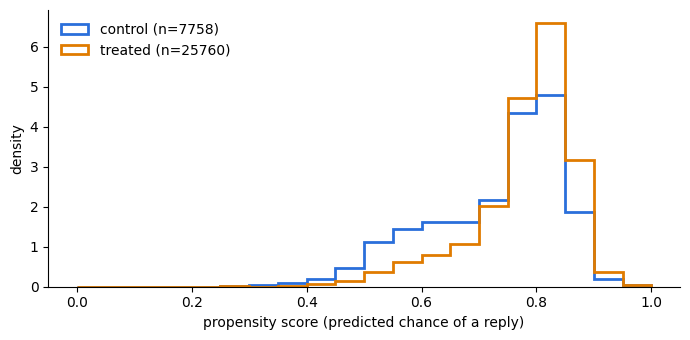

,bin,control,treated
1,0.05-0.10,0,1
2,0.10-0.15,1,2
3,0.15-0.20,1,0
4,0.20-0.25,2,2
5,0.25-0.30,5,9
6,0.30-0.35,14,7
7,0.35-0.40,37,22
8,0.40-0.45,78,75
9,0.45-0.50,177,179
10,0.50-0.55,433,476


In [12]:
import matplotlib.pyplot as plt
bins = np.linspace(0, 1, 21)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(e_hat[~t1], bins=bins, density=True, histtype="step", linewidth=2, color="#2a6fdb", label=f"control (n={int((~t1).sum())})")
ax.hist(e_hat[t1], bins=bins, density=True, histtype="step", linewidth=2, color="#e07b00", label=f"treated (n={int(t1.sum())})")
ax.set_xlabel("propensity score (predicted chance of a reply)"); ax.set_ylabel("density"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
h = pd.DataFrame({"bin": [f"{a:.2f}-{b:.2f}" for a, b in zip(bins[:-1], bins[1:])],
                  "control": np.histogram(e_hat[~t1], bins)[0], "treated": np.histogram(e_hat[t1], bins)[0]})
display(h[(h.control + h.treated) > 0])

**What the output shows.** Replied newcomers cluster at higher scores (most between 0.75 and 0.90), and
non-replied ones are spread a bit lower, but both groups have people in every bin from 0.25 to 1.00. There are
hundreds of non-replied newcomers even in the busiest bins, so every replied person has comparable people to be
compared with.

### 7.2 Ablation: which covariate blocks matter (table A7)
Each row fits the propensity score with only some blocks. If the ATT barely moves, the result does not hinge on
one block.

**What this checks.** Whether the result depends on one particular kind of background fact.

In [13]:
display(t("A7_feature_ablation").round(4))

,Model,p,AUC,ATT,CI_lo,CI_hi,Sig,SMD_gt_0.1
0,Full model (E+Qtext+Qpersp+Qtype+Emb+T),164,0.6256,0.0184,0.0070,0.0303,*,0
1,Full - Qtype (no LLM annotation),159,0.6174,0.0205,0.0099,0.0324,*,0
2,Full - temporal,102,0.6166,0.0198,0.0097,0.0308,*,0
3,Full - embeddings,144,0.6192,0.0198,0.0086,0.0297,*,0
4,Full - Qtext,127,0.6241,0.0189,0.0084,0.0287,*,0
5,Full - Qpersp,156,0.6261,0.0183,0.0070,0.0294,*,0
6,Full + full emb (1024d),1168,0.6028,0.0293,0.0187,0.0399,*,15
7,Edit history only,32,0.5328,0.0311,0.0222,0.0403,*,0
8,E + embeddings,52,0.6060,0.0225,0.0118,0.0332,*,0
9,E + Qtext,69,0.5810,0.0283,0.0174,0.0379,*,0


**What the output shows.** Dropping any one block keeps the ATT between 0.018 and 0.021, all significant.
Using fewer facts (for example edit history only, 0.031) gives larger effects, which is what one expects when
less of the head start of replied newcomers is removed. Two rows to note: using the full 1,024-number embedding
leaves 15 facts unbalanced, so the 20-summary version is the better choice; adding mentor features predicts
replies much better (AUC 0.79, since some mentors reply far more than others) and gives 0.015, just short of
significance (CI -0.0001 to 0.0323). The CI of the "Full model" row (0.0070 to 0.0303) differs slightly from
Table B (0.0062 to 0.0299)
only because it uses a different set of random bootstrap draws; the point estimate is identical.

### 7.3 Robustness settings
Each row re-runs the whole estimate (new propensity score, new strata, 500 bootstrap draws) on a different
sample or treatment definition: without the D10 restriction, treatment = a reply from the assigned mentor
compared with no reply at all (newcomers answered only by others are left out, and the window starts at the
mentor's first reply; `mentor_reply_versions.csv` shows the simpler versions), without late-fetched people, only
questions at least 30 days before the cutoff, also people without a full 14-day follow-up (the main sample before
that rule), only people with no imputed text values, only people also in the paper sample.
Then: number of strata (C1), trimming extreme propensity scores (C3), and other pseudo start times for the
control group (C7).

**What this checks.** Whether the main result survives reasonable changes to the sample, the treatment
definition and the method. The pseudo start time: replied newcomers' 14 days are counted from the reply;
non-replied newcomers have no reply, so their 14 days start at the question time plus a delay drawn at random
from the real reply delays.

In [14]:
display(t("robustness").round(4))
display(t("C1_strata_sensitivity").round(4).head(12))
display(t("C3_ps_trimming").round(4))
display(t("C7_pseudo_time").round(4))

,Spec,N,Treated,AUC,ATT,CI_lo,CI_hi,Sig,Ctrl_mean,Treat_mean
0,Main (D10 sample),33518,25760,0.6256,0.0184,0.0070,0.0303,*,0.1754,0.2217
1,No D10 restriction (R2.5),34419,26456,0.6248,0.0199,0.0088,0.0311,*,0.1811,0.2290
2,Treatment = assigned mentor replied (vs no reply),32321,24563,0.6248,0.0187,0.0077,0.0310,*,0.1754,0.2224
3,Exclude late-fetched askers (M3),31148,23972,0.6217,0.0186,0.0077,0.0302,*,0.1538,0.1927
4,Questions ≥ 30 days before the cutoff (I-11),32949,25319,0.6260,0.0176,0.0062,0.0285,*,0.1750,0.2207
5,Also people without a full 14-day follow-up (before I-10),34073,26176,0.6246,0.0208,0.0102,0.0305,*,0.1751,0.2223
6,Complete text annotations (no imputation),33473,25743,0.6238,0.0195,0.0094,0.0310,*,0.1757,0.2218
7,Askers also in the paper sample,31840,24689,0.6200,0.0158,0.0034,0.0266,*,0.1776,0.2201


,Outcome,Strata,ATT,CI_lo,CI_hi,Sig
0,1+_mainspace_edit_14d,5,0.0201,0.0094,0.0320,*
1,1+_mainspace_edit_14d,10,0.0184,0.0082,0.0298,*
2,1+_mainspace_edit_14d,20,0.0174,0.0060,0.0287,*
3,n_mainspace_edits_14d,5,0.8248,0.0637,1.5354,*
4,n_mainspace_edits_14d,10,0.7843,-0.0214,1.5895,
5,n_mainspace_edits_14d,20,0.7303,-0.0503,1.5489,
6,active_days_30d,5,0.1476,0.0605,0.2317,*
7,active_days_30d,10,0.1349,0.0460,0.2262,*
8,active_days_30d,20,0.1251,0.0293,0.2154,*
9,unique_namespace_14d,5,0.0307,0.0078,0.0519,*


,Range,Trimmed,N_remain,ATT,CI_lo,CI_hi,Sig
0,"[0.01,0.99]",14,33504,0.0186,0.0081,0.0296,*
1,"[0.05,0.95]",54,33464,0.0189,0.0072,0.0291,*
2,"[0.1,0.9]",617,32901,0.0205,0.0089,0.0310,*
3,"[0.15,0.85]",5430,28088,0.0174,0.0051,0.0281,*


,Strategy,ATT,CI_lo,CI_hi,N,Sig
0,Random draw (main),0.0184,0.0062,0.0299,NaN,*
1,Median lag,0.0177,0.0069,0.0281,33518.0,*
2,25th pctl lag,-0.0115,-0.0245,-0.0010,33518.0,*
3,75th pctl lag,0.0374,0.0267,0.0476,33514.0,*
4,Zero lag (immediate),-0.0814,-0.0943,-0.0710,33518.0,*
5,Multi-draw avg,0.0170,0.0073,0.0280,33518.0,*


**What the output shows.** All 8 sample and treatment settings give an ATT between 0.016 and 0.021, all
significant; the row that also keeps the 555 people without a full 14-day follow-up gives 0.0208, the main value
before this rule. Using 5, 10 or 20 strata gives nearly the same result, and so does trimming extreme scores
(0.017 to 0.021). The pseudo start time matters more, and a reviewer should see this. With the main random draw,
the median delay or the average of many draws, the ATT is 0.017 to 0.018. With a short fixed delay (25th
percentile) it is slightly negative (-0.012, CI -0.025 to -0.001), with a long one (75th percentile) 0.037, and
with zero delay it turns clearly negative (-0.081). This is because non-replied newcomers are most active right after asking, so starting their
clock earlier counts more of their edits. The random draw gives both groups the same spread of start delays,
but the fixed-delay rows show that the result depends on the clock; this is the main open question for the
design (a risk-set matching analysis is planned).

### 7.4 Outcome windows
Main outcome measured over 7 to 180 days. `ATT` uses only people in `in_sample` whose full window lies before the
data cutoff, with the propensity score refitted on them. `ATT_main_strata` uses the people of the main analysis
sample whose window is observed, with the main strata kept fixed (table C4).

**What this checks.** Whether the effect holds over shorter and longer periods, and whether people whose window
is cut off by the data end (2026-04-20) change the result.

In [15]:
w = t("window_followup_complete")[["window", "N", "ATT", "CI_lo", "CI_hi", "Sig"]].merge(
    t("C4_window_sensitivity")[["window", "ATT"]], on="window", suffixes=("", "_main_strata"))
display(w.round(4))

,window,N,ATT,CI_lo,CI_hi,Sig,ATT_main_strata
0,7,33793,0.0201,0.0099,0.0314,*,0.0191
1,14,33518,0.0184,0.0080,0.0299,*,0.0184
2,21,33272,0.0186,0.0073,0.0296,*,0.0180
3,28,32956,0.0179,0.0064,0.0295,*,0.0172
4,30,32883,0.0166,0.0043,0.0290,*,0.0161
5,60,31665,0.0168,0.0043,0.0295,*,0.0159
6,180,26676,0.0163,0.0033,0.0283,*,0.0153


**What the output shows.** The effect stays positive and significant from 7 to 180 days (0.020 at 7 days, 0.016
at 180 days), and the two columns agree to within 0.001. Every number here uses only people whose window is fully
observed. Before this rule the paper counted everyone, including people whose window was cut off by the data end;
that gave somewhat larger values (14 days: 0.0208; 180 days: 0.0228).

### 7.5 Subgroups (Table 5) and interaction tests (a2)
Subgroup ATTs use 5 strata inside each subgroup. A subgroup effect that looks larger is only meaningful if the
interaction test (difference between groups, with a bootstrap CI) excludes 0.

**What this checks.** For which kinds of questions a reply seems to help, and whether those differences are
real.

In [16]:
sg = t("subgroup_att")
display(sg[sg.Outcome.str.contains("1\\+|primary", regex=True)].round(4))
display(t("subgroup_diagnostics").round(4))
a2 = t("a2_interaction_results")
display(a2[a2.DV == "1+_mainspace_edit_14d"].round(4))

,Subgroup,N,T,C,Outcome,N_outcome,Ctrl_mean,Treat_mean,ATT,CI_lo,CI_hi,Cohen_d,Sig
0,Full sample,33518,25760,7758,1+_mainspace_14d,33518,0.1754,0.2217,0.0228,0.0113,0.0342,0.0599,*
6,Technical,15750,12662,3088,1+_mainspace_14d,15750,0.1937,0.2251,0.0241,0.0068,0.0414,0.0611,*
12,Referent (Q2),4528,3605,923,1+_mainspace_14d,4528,0.1668,0.1584,-0.0155,-0.0453,0.0128,-0.0417,
18,Appraisal (Q3),1864,1440,424,1+_mainspace_14d,1864,0.2948,0.3375,0.0399,-0.0118,0.0910,0.0875,
24,Normative (Q4),5974,4939,1035,1+_mainspace_14d,5974,0.2966,0.3321,0.0343,0.0032,0.0662,0.0751,*
30,Non-substantive,6424,3944,2480,1+_mainspace_14d,6424,0.0931,0.1032,0.0054,-0.0115,0.0208,0.0187,
36,Own work (Q5=Y),7688,6107,1581,1+_mainspace_14d,7688,0.2758,0.3173,0.0343,0.0088,0.0603,0.0768,*
42,No own work (Q5=N),25830,19653,6177,1+_mainspace_14d,25830,0.1497,0.1919,0.0203,0.0076,0.0322,0.0569,*


,Subgroup,N,Treated,Control,T_pct,AUC,K,SMD_bad
0,Full sample,33518,25760,7758,76.9,0.6174,5,0
1,Technical,15750,12662,3088,80.4,0.5584,5,0
2,Referent (Q2),4528,3605,923,79.6,0.5552,5,1
3,Appraisal (Q3),1864,1440,424,77.3,0.5476,5,8
4,Normative (Q4),5974,4939,1035,82.7,0.5076,5,0
5,Non-substantive,6424,3944,2480,61.4,0.6048,5,0
6,Own work (Q5=Y),7688,6107,1581,79.4,0.5469,5,0
7,No own work (Q5=N),25830,19653,6177,76.1,0.6334,5,0


,moderator,mod_type,DV,beta_D,beta_DxM,boot_mean,boot_SE,CI_lo,CI_hi,sig
0,M1: Substantive (Q1),binary,1+_mainspace_edit_14d,0.0092,0.0111,0.0117,0.0100,-0.0076,0.0306,False
5,M2: Info-seeking breadth (Q2+Q3+Q4),continuous (z),1+_mainspace_edit_14d,0.0181,-0.0036,-0.0033,0.0059,-0.0138,0.0082,False
10,M3: Own work (Q5),binary,1+_mainspace_edit_14d,0.0150,0.0164,0.0160,0.0140,-0.0118,0.0439,False
15,M4: Reply propensity,continuous (z),1+_mainspace_edit_14d,0.0176,0.0019,0.0021,0.0042,-0.0065,0.0095,False
20,M5: Referent (Q2),binary,1+_mainspace_edit_14d,0.0239,-0.0419,-0.0416,0.0146,-0.0692,-0.0120,True
25,M6: Appraisal (Q3),binary,1+_mainspace_edit_14d,0.0178,0.0184,0.0182,0.0270,-0.0332,0.0723,False
30,M7: Normative (Q4),binary,1+_mainspace_edit_14d,0.0159,0.0117,0.0140,0.0160,-0.0184,0.0448,False
35,M8: Pure technical,binary,1+_mainspace_edit_14d,0.0173,0.0033,0.0033,0.0105,-0.0163,0.0253,False


**What the output shows.** The "Full sample" row here is 0.0228, not 0.0184, because subgroup models use 5
strata and leave out the question-type facts (which define the subgroups); that is expected. The effect is
significant for technical (0.024), normative (0.034), own-work (0.034) and no-own-work (0.020) questions, and
not significant for referent, appraisal and non-substantive questions. But the interaction tests show that only
one difference is reliable: for referent questions the effect is about 4 points smaller (CI -0.069 to -0.012).
Two cautions: the appraisal subgroup is small (1,864 people) and still has 8 unbalanced facts, so its estimate is
rough; and with 8 tests, one significant result could partly be chance.

### 7.6 Reply features (Tables 6 and 7)
Within treated people only: a mixed model of the main outcome on standardized reply features (random intercept
per mentor), controlling for all covariates. `q_BH` is the Benjamini-Hochberg adjusted p value. These are
associations, not causal effects.

**What this checks.** Among replied newcomers, which features of the reply go along with more editing. `VIF`
measures how much a feature duplicates others; very high values make coefficients unstable.

In [17]:
display(t("reply_association").sort_values("p").round(4))
display(t("reply_vif").round(3))

,Feature,Beta_std,SE,z,p,Sig,ICC,method,q_BH
10,Reply lag (hours),-0.0359,0.0023,-15.6988,0.0000,***,0.0,mixedlm,0.0000
18,Q-R semantic similarity,0.0143,0.0026,5.3852,0.0000,***,0.0,mixedlm,0.0000
3,"""We"" rate (per word)",-0.0059,0.0023,-2.6017,0.0093,**,0.0,mixedlm,0.0475
4,VADER compound sentiment,0.0077,0.0030,2.5715,0.0101,*,0.0,mixedlm,0.0475
5,TextBlob subjectivity,0.0062,0.0025,2.4980,0.0125,*,0.0,mixedlm,0.0475
16,Has list,0.0048,0.0023,2.0531,0.0401,*,0.0,mixedlm,0.1269
17,Question marks in reply,0.0042,0.0024,1.7555,0.0792,,0.0,mixedlm,0.2021
8,Policy references,-0.0043,0.0025,-1.7219,0.0851,,0.0,mixedlm,0.2021
1,"""You"" rate (per word)",-0.0032,0.0024,-1.3422,0.1795,,0.0,mixedlm,0.3790
0,Reply word count,-0.0041,0.0036,-1.1340,0.2568,,0.0,mixedlm,0.4879


,feature,vif,dropped
0,Reply word count,2.316,False
1,"""You"" rate (per word)",1.101,False
2,"""I"" rate (per word)",1.104,False
3,"""We"" rate (per word)",1.016,False
4,VADER compound sentiment,1.709,False
5,TextBlob subjectivity,1.229,False
6,Flesch-Kincaid grade,1.296,False
7,Imperative sentences,1.334,False
8,Resource links (total),52.229,True
9,Wikilinks,51.621,True


**What the output shows.** The clearest pattern is speed: slower replies go with less editing (coefficient
-0.036 per standard deviation, the strongest by far). Replies that are closer in meaning to the question go with
more editing (+0.014). After correcting for many tests (q below 0.05), these two remain, plus three small terms
just under the line (q = 0.048): a negative "we" rate, and positive sentiment and subjectivity. Two technical notes: `Resource links` and `Wikilinks` were dropped because they nearly
duplicate each other (VIF about 52); and `ICC` is 0.0, meaning the model found no extra mentor-to-mentor
variation, so the mixed model gives the same answer as an ordinary regression here.

### 7.7 Long-term effect on one cohort (paper Table "later") and the monthly figure
`followup.py` analysis d. One cohort: newcomers whose start time (the reply, or the pseudo-reply time for
controls) is at least 365 days before the cutoff, so every period is observed for the same people. For each of the
periods days 1-14, 15-28, 29-60, 61-180 and 181-365 the outcome is at least one (or at least five) article edits
in that period. `q_BH` is the Benjamini-Hochberg q value over the eight later estimates (days 1-14 are only a
reference). The cell below rebuilds the cohort, the edit counts per period, the propensity score and the ATT with
plain code, independently of the pipeline, and recomputes the q values from the pipeline's bootstrap p values.

**What this checks.** That the long-term table in the paper is computed on the people and periods it says, and
that the multiple-testing correction covers exactly the eight later estimates.

In [18]:
import pyarrow.dataset as pads
LT = t("followup_cohort_periods")
s5 = pd.read_parquet(config.INTERIM / "m5" / "sample.parquet", columns=["first_question_revid", "mentee_uid", "anchor"])
s5 = s5.drop_duplicates("first_question_revid").set_index("first_question_revid").loc[D["cid_order"].astype(np.int64)]
anc = pd.to_datetime(s5.anchor, utc=True).dt.tz_localize(None).to_numpy(dtype="datetime64[s]")
cutoff = np.datetime64(pd.Timestamp(config.DATA_CUTOFF).tz_localize(None), "s")
coh = anc + np.timedelta64(365, "D") <= cutoff
uid_c = s5.mentee_uid.astype(np.int64).to_numpy()[coh]
dc = d[coh]
print(f"cohort: {int(coh.sum())} people ({int(dc.sum())} treated); latest start time {pd.Timestamp(anc[coh].max())}")
ed = pads.dataset(config.INTERIM / "m3" / "mentee_edits").to_table(columns=["uid", "timestamp", "ns"],
        filter=(pads.field("uid").isin(list(uid_c))) & (pads.field("ns") == 0)).to_pandas()
pos = {u: i for i, u in enumerate(uid_c)}
ei = ed.uid.map(pos).to_numpy()
edays = (pd.to_datetime(ed.timestamp, utc=True).dt.tz_localize(None).to_numpy(dtype="datetime64[s]") - anc[coh][ei]) / np.timedelta64(1, "D")
Xc = StandardScaler().fit_transform(X[coh][:, X[coh].std(axis=0) > 0])
e_c = cross_val_predict(LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, random_state=42), Xc, dc,
                        cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]
s_c = pd.qcut(e_c, 10, labels=False, duplicates="drop").astype(int)
rows = []
for period, lo, hi in [("days 1-14", 0, 14), ("days 15-28", 14, 28), ("days 29-60", 28, 60), ("days 61-180", 60, 180), ("days 181-365", 180, 365)]:
    n = np.bincount(ei[(edays > lo) & (edays <= hi)], minlength=len(uid_c))
    for thr in (1, 5):
        y = (n >= thr).astype(float)
        rows.append({"period": period, "threshold": f"{thr}+", "N_mine": len(y), "treated_mean_mine": y[dc == 1].mean(),
                     "ATT_mine": my_att(y, dc, s_c)})
MINE = pd.DataFrame(rows).merge(LT, on=["period", "threshold"])
later = MINE.period != "days 1-14"
from statsmodels.stats.multitest import multipletests
MINE["q_mine"] = np.nan
MINE.loc[later, "q_mine"] = multipletests(MINE.loc[later, "p_boot"], method="fdr_bh")[1]
display(MINE[["period", "threshold", "N", "N_mine", "Treat_mean", "treated_mean_mine", "ATT", "ATT_mine", "CI_lo", "CI_hi",
              "p_boot", "q_BH", "q_mine"]].round(4))
ck.add("long-term table: cohort size, treated means and ATTs equal an independent recomputation",
       bool((MINE.N == MINE.N_mine).all() and np.allclose(MINE.Treat_mean, MINE.treated_mean_mine)
            and np.allclose(MINE.ATT, MINE.ATT_mine, atol=1e-10)))
ck.add("long-term table: q values are BH over exactly the eight later estimates",
       bool(np.allclose(MINE.loc[later, "q_BH"], MINE.loc[later, "q_mine"]) and MINE.loc[~later, "q_BH"].isna().all()))
MO = t("followup_monthly")
mi = np.ceil(edays / 30).astype(int)
okm = (edays > 0) & (mi >= 1) & (mi <= 12)
YM = np.zeros((len(uid_c), 12)); YM[ei[okm], mi[okm] - 1] = 1
ck.add("monthly figure: treated share per month equals an independent recomputation",
       bool(np.allclose(MO.Treat_share, YM[dc == 1].mean(axis=0))))
display(MO[["month", "Treat_share", "Ctrl_share_reweighted"]].round(3).T)

cohort: 19512 people (14858 treated); latest start time 2025-04-20 13:33:36


,period,threshold,N,N_mine,Treat_mean,treated_mean_mine,ATT,ATT_mine,CI_lo,CI_hi,p_boot,q_BH,q_mine
0,days 1-14,1+,19512,19512,0.2067,0.2067,0.0249,0.0249,0.0106,0.0389,0.000,NaN,NaN
1,days 1-14,5+,19512,19512,0.0966,0.0966,0.0164,0.0164,0.0061,0.0263,0.001,NaN,NaN
2,days 15-28,1+,19512,19512,0.0896,0.0896,0.0063,0.0063,-0.0039,0.0161,0.219,0.2503,0.2503
3,days 15-28,5+,19512,19512,0.0442,0.0442,0.0043,0.0043,-0.0032,0.0115,0.262,0.2620,0.2620
4,days 29-60,1+,19512,19512,0.0989,0.0989,0.0084,0.0084,-0.0025,0.0185,0.134,0.2503,0.2503
5,days 29-60,5+,19512,19512,0.0487,0.0487,0.0050,0.0050,-0.0024,0.0127,0.201,0.2503,0.2503
6,days 61-180,1+,19512,19512,0.1172,0.1172,0.0101,0.0101,-0.0010,0.0222,0.084,0.2240,0.2240
7,days 61-180,5+,19512,19512,0.0645,0.0645,0.0077,0.0077,-0.0007,0.0163,0.079,0.2240,0.2240
8,days 181-365,1+,19512,19512,0.0917,0.0917,0.0146,0.0146,0.0046,0.0244,0.005,0.0400,0.0400
9,days 181-365,5+,19512,19512,0.0509,0.0509,0.0055,0.0055,-0.0026,0.0132,0.161,0.2503,0.2503


  [OK ] long-term table: cohort size, treated means and ATTs equal an independent recomputation
  [OK ] long-term table: q values are BH over exactly the eight later estimates
  [OK ] monthly figure: treated share per month equals an independent recomputation


,0,1,2,3,4,5,6,7,8,9,10,11
month,1.000,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000,10.000,11.000,12.000
Treat_share,0.225,0.095,0.073,0.064,0.055,0.051,0.045,0.044,0.042,0.038,0.035,0.035
Ctrl_share_reweighted,0.206,0.085,0.065,0.051,0.052,0.047,0.039,0.035,0.034,0.035,0.031,0.029


**What the output shows.** The cohort has 19,512 people (14,858 treated); the latest start time is
2025-04-20, one year before the cutoff. The recomputed cohort, treated means and ATTs equal the pipeline's for all
ten rows, and the q values equal a Benjamini-Hochberg correction over the eight later rows. One later estimate has
q below 0.05: at least one article edit in days 181-365, +1.46 points (9.2% of treated against 7.7% of reweighted
controls). In days 1-14 this cohort's effect is +2.49 points, larger than the 1.84 of the full sample. The monthly
shares fall from 22.5% of treated people in month 1 to 9.5% in month 2 and 3.5% in month 12.

### 7.8 Edit quality (paper paragraph "Edit quality", Appendix Tables "quality" and "quality_self")
`quality.py`. An article edit counts as rejected if another editor reverted it within 48 hours. Every newcomer is
in one of three groups by their article edits in the 14 days after the start time: (1) no article edit, (2) at
least 80% of the edits kept, (3) less than 80% kept. Edits that the newcomer reverted themself are left out with
the reverting edit. Only newcomers whose 14-day window ends at least 48 hours before the cutoff are used.

**What this checks.** That the three groups cover everyone exactly once (their shares add up to 1 and their ATTs
add up to 0), that group 1 differs from "no article edit" in the main outcome only by the newcomers whose edits were
all reverted by themselves, and the counts quoted in the appendix.

In [19]:
QC, QS, QR = t("quality_cuts"), t("quality_self_versions"), t("quality_revert_stats")
display(QC[["cut", "g1_Ctrl_reweighted", "g1_ATT", "g2_Ctrl_reweighted", "g2_ATT", "g2_CI_lo", "g2_CI_hi",
            "g3_Ctrl_reweighted", "g3_ATT", "g3_CI_lo", "g3_CI_hi"]].round(4))
display(QS.round(4)); display(QR.T)
ck.add("edit quality: group shares add up to 1 and group ATTs add up to 0 for every cut",
       bool(np.allclose(QC.g1_Ctrl_reweighted + QC.g2_Ctrl_reweighted + QC.g3_Ctrl_reweighted, 1)
            and np.allclose(QC.g1_ATT + QC.g2_ATT + QC.g3_ATT, 0, atol=1e-10)))
s5q = pd.read_parquet(config.INTERIM / "m5" / "sample.parquet", columns=["first_question_revid", "anchor"])
s5q = s5q.drop_duplicates("first_question_revid").set_index("first_question_revid").loc[D["cid_order"].astype(np.int64)]
aq = pd.to_datetime(s5q.anchor, utc=True).dt.tz_localize(None)
fq = (aq + pd.Timedelta(days=16) <= pd.Timestamp(config.DATA_CUTOFF).tz_localize(None)).to_numpy()
no_edit_treated = 1 - D["oc_primary"][fq][d[fq] == 1].mean()
gap = QC.g1_Treat.iloc[0] - no_edit_treated
print(f"N with 48 hours after the window: {int(fq.sum())} (quality.py {int(QR.N[0])}); treated share in group 1 {QC.g1_Treat.iloc[0]:.5f}, "
      f"treated share without an article edit {no_edit_treated:.5f}")
ck.add("edit quality: same sample as the 48-hour rule needs, and group 1 = no article edit up to the self-revert-only newcomers",
       bool(int(fq.sum()) == int(QR.N[0]) and 0 <= gap * d[fq].sum() <= QR.newcomers_only_self_reverted_pairs[0] + 1e-9))

,cut,g1_Ctrl_reweighted,g1_ATT,g2_Ctrl_reweighted,g2_ATT,g2_CI_lo,g2_CI_hi,g3_Ctrl_reweighted,g3_ATT,g3_CI_lo,g3_CI_hi
0,at least one edit,0.7981,-0.0192,0.1790,0.0203,0.0100,0.0317,0.0229,-0.0011,-0.0048,0.0028
1,50%,0.7981,-0.0192,0.1707,0.0199,0.0103,0.0302,0.0312,-0.0007,-0.0050,0.0039
2,60%,0.7981,-0.0192,0.1641,0.0195,0.0100,0.0294,0.0378,-0.0003,-0.0052,0.0053
3,70%,0.7981,-0.0192,0.1590,0.0182,0.0088,0.0279,0.0429,0.0010,-0.0041,0.0071
4,80%,0.7981,-0.0192,0.1520,0.0189,0.0096,0.0288,0.0499,0.0004,-0.0054,0.0068
5,90%,0.7981,-0.0192,0.1440,0.0150,0.0066,0.0249,0.0579,0.0042,-0.0018,0.0117
6,all edits,0.7981,-0.0192,0.1289,0.0110,0.0021,0.0201,0.0730,0.0082,0.0013,0.0163


,self_reverts,unmatched,ctrl_mean_rejected_share,g2_Ctrl_reweighted,g2_Treat,g2_ATT,g2_CI_lo,g2_CI_hi,g2_Sig,g3_Ctrl_reweighted,g3_Treat,g3_ATT,g3_CI_lo,g3_CI_hi,g3_Sig
0,leave out,rejected,0.2080,0.1520,0.1708,0.0189,0.0096,0.0288,*,0.0499,0.0503,0.0004,-0.0054,0.0068,NaN
1,leave out,kept,0.2060,0.1524,0.1716,0.0192,0.0096,0.0292,*,0.0495,0.0496,0.0001,-0.0053,0.0065,NaN
2,rejected,rejected,0.2148,0.1503,0.1691,0.0188,0.0096,0.0288,*,0.0527,0.0526,-0.0001,-0.0059,0.0067,NaN
3,kept,rejected,0.2044,0.1535,0.1716,0.0181,0.0088,0.0279,*,0.0495,0.0501,0.0006,-0.0049,0.0072,NaN


,0
N,33452.000000
treated,25709.000000
window_article_edits,132964.000000
tagged,16381.000000
tagged_matched,16152.000000
reverted_within_48h,12666.000000
reverted_by_newcomer,1375.000000
median_minutes_self,1.450000
median_minutes_others,104.716667
share_self_within_10_min,0.827636


  [OK ] edit quality: group shares add up to 1 and group ATTs add up to 0 for every cut
N with 48 hours after the window: 33452 (quality.py 33452); treated share in group 1 0.77887, treated share without an article edit 0.77833
  [OK ] edit quality: same sample as the 48-hour rule needs, and group 1 = no article edit up to the self-revert-only newcomers


True

**What the output shows.** 33,452 newcomers have 48 hours of observation after their 14-day window. In every row the
three group shares add up to 1 and the three ATTs add up to 0. Group 1 holds 77.89% of treated newcomers, against
77.83% without any article edit; the difference is the newcomers whose only edits were reverted by themselves (21 in
both groups together). With the 80% cut, group 2 rises by 1.9 points and group 3 does not change (+0.0, CI -0.5 to
+0.7). Of 16,381 tagged article edits in the windows, 98.6% were matched to a reverting revision; of the 12,666
reverted within 48 hours, 1,375 were reverted by the newcomer, a median of 1.5 minutes after the edit.

### 7.9 Mentor pool over time (paper Appendix "Mentor Pool over Time", Figure "mentor_pool")
`descriptive.py` part e. Month-end counts of mentors in the automatic assignment pool and of mentors who take manual
claims only (from the M1 roster history), the number of main-sample newcomers who asked in each month, and that
number divided by the automatic pool.

**What this checks.** The month-end counts are recomputed here from the M1 status periods with a different method
(a month-by-period matrix instead of a loop), and the askers per month from the M7 dataset, not from the pipeline's
sample function. The counts quoted in the paper are printed, and the two published pool sizes (Phabricator T323048:
83 in November 2022, 187 in February 2025) are compared with ours.

In [20]:
MP, MS = t("descriptive_mentor_pool_by_month"), t("descriptive_mentor_pool_summary")
per = pd.read_parquet(config.INTERIM / "m1" / "mentor_periods.parquet")
ps = pd.to_datetime(per.start, utc=True).to_numpy()
pe = pd.to_datetime(per.end, utc=True).fillna(pd.Timestamp("2100-01-01", tz="UTC")).to_numpy()
ends = (pd.to_datetime(MP.month + "-01", utc=True) + pd.offsets.MonthEnd(0) + pd.Timedelta(hours=23, minutes=59)).to_numpy()
on = (ps[None, :] <= ends[:, None]) & (pe[None, :] > ends[:, None])
auto_ = (on & (per.in_auto_pool == True).to_numpy()[None, :]).sum(1)   # noqa: E712
man_ = (on & (per.in_auto_pool == False).to_numpy()[None, :]).sum(1)   # noqa: E712
qm = pd.to_datetime(pd.Series(D["q_ts"]), utc=True).dt.strftime("%Y-%m")
ask = qm.value_counts().reindex(MP.month).to_numpy()
print("months:", len(MP), "| automatic pool equal:", bool((auto_ == MP.auto_pool).all()),
      "| manual only equal:", bool((man_ == MP.manual_only).all()), "| askers equal:", bool((ask == MP.askers).all()))
ck.add("mentor pool: month-end counts and askers per month recomputed independently",
       bool((auto_ == MP.auto_pool).all() and (man_ == MP.manual_only).all() and (ask == MP.askers).all()
            and np.allclose(ask / auto_, MP.askers_per_pool_mentor)))
ml = pd.read_parquet(config.INTERIM / "m1" / "mentor_list.parquet")
nm = pd.Series(D["mentor_ids"]).astype(str).nunique()
print(f"mentors ever {ml.mentor_uid.nunique()} (automatic pool {int(ml.ever_in_auto_pool.sum())}); at the cutoff {int(ml.is_current.sum())}; "
      f"main-sample mentors {nm}")
pub = MP.set_index("month").loc[["2022-11", "2025-02"], "auto_pool"]
print("published 83 and 187 against ours:", pub.to_dict())
ck.add("mentor pool: summary counts match, and ours are within 2 of the published pool sizes",
       bool(ml.mentor_uid.nunique() == MS.mentors_ever[0] and nm == MS.sample_mentors[0]
            and abs(pub["2022-11"] - 83) <= 2 and abs(pub["2025-02"] - 187) <= 2))
display(MP[MP.month.isin(["2021-05", "2022-03", "2022-11", "2023-03", "2023-04", "2023-07", "2023-10", "2025-02", "2025-03", "2026-03"])].round(2))

months: 59 | automatic pool equal: True | manual only equal: True | askers equal: True
  [OK ] mentor pool: month-end counts and askers per month recomputed independently


mentors ever 450 (automatic pool 443); at the cutoff 291; main-sample mentors 400
published 83 and 187 against ours: {'2022-11': 85, '2025-02': 188}
  [OK ] mentor pool: summary counts match, and ours are within 2 of the published pool sizes


,month,listed,auto_pool,manual_only,askers,mentors_assigned,reply_share,askers_per_pool_mentor
0,2021-05,14,14,0,11,5,0.91,0.79
10,2022-03,92,85,7,179,76,0.88,2.11
18,2022-11,95,85,10,214,82,0.68,2.52
22,2023-03,105,91,14,208,73,0.75,2.29
23,2023-04,171,157,14,186,98,0.75,1.18
26,2023-07,179,157,22,294,128,0.73,1.87
29,2023-10,177,136,41,685,140,0.77,5.04
45,2025-02,240,188,52,1038,166,0.73,5.52
46,2025-03,241,186,55,1241,165,0.75,6.67
58,2026-03,288,208,80,1238,183,0.79,5.95


**What the output shows.** For all 59 months the recomputed automatic-pool and manual-only counts and the askers per
month equal the pipeline's. 450 mentors were on the list at some time (443 of them in the automatic pool) and 291
at the cutoff; the main-sample newcomers were assigned to 400 of them. The automatic pool had 85 mentors in November
2022 and 188 in February 2025 (published: 83 and 187), and rose from 91 to 157 in April 2023. Askers per pool mentor
rose from 1.2 to 1.9 in July 2023, from 2.6 to 5.0 in October 2023 and from 4.3 to 6.7 between January and March
2025, the months in which the visible share rose.

## 8. Summary (written to results/m8_report.json)

**What this checks.** All checks in one list, plus the main numbers saved to a small file for later modules.

In [21]:
ck.report()
b0 = B.iloc[0]
rep = {"N": int(len(d)), "treated": int(d.sum()), "AUC": float(auc), "ATT_primary": float(b0.ATT), "CI": [float(b0.CI_lo), float(b0.CI_hi)],
       "ATT_primary_reproduced": float(ATT), "naive_primary": float(b0.Naive), "e_value_corrected": float(fixed.e_point),
       "e_value_ci": float(fixed.e_ci), "n_smd_after_gt_0.1": int((SMD.SMD_after > 0.1).sum()),
       "checks_passed": sum(ok for _, ok in ck.items), "checks_total": len(ck.items),
       "failed_checks": [n for n, ok in ck.items if not ok], "seed": SEED, "random_people": [int(u) for u in RND.mentee_uid]}
(config.RESULTS / "m8_report.json").write_text(json.dumps(rep, indent=1))
print(json.dumps(rep, indent=1))
print(f"\nMain result: a reply raises the chance of at least one article edit in the next 14 days by {b0.ATT * 100:.2f} percentage points "
      f"(95% CI {b0.CI_lo * 100:.2f} to {b0.CI_hi * 100:.2f}); the unadjusted difference is {b0.Naive * 100:.2f} points.")


27 / 27 checks passed
{
 "N": 33518,
 "treated": 25760,
 "AUC": 0.6255685275387939,
 "ATT_primary": 0.0184435550432917,
 "CI": [
  0.0062226011535529,
  0.0299280563030223
 ],
 "ATT_primary_reproduced": 0.018443555043291742,
 "naive_primary": 0.0462296783604662,
 "e_value_corrected": 1.405391339185525,
 "e_value_ci": 1.2012713598055913,
 "n_smd_after_gt_0.1": 0,
 "checks_passed": 27,
 "checks_total": 27,
 "failed_checks": [],
 "seed": 0,
 "random_people": [
  49455045,
  47114047,
  51333622,
  48066394,
  53066071
 ]
}

Main result: a reply raises the chance of at least one article edit in the next 14 days by 1.84 percentage points (95% CI 0.62 to 2.99); the unadjusted difference is 4.62 points.


**What the output shows.** All 27 checks pass. In the run on the final data (cutoff 2026-04-20T14:00Z), a reply from the mentor raises the
chance of at least one article edit in the next 14 days by 1.84 percentage points (95% CI 0.62 to 2.99), from a
base of 17.5% among non-replied newcomers (a relative increase of about 10%). The raw difference is 4.62 points;
the rest is explained by replied newcomers already being more active. The full bootstrap in
`results/m8/full_bootstrap.csv` (not shown above), which also re-estimates the scores in each draw, gives a CI
of 1.17 to 3.20 points, so the conclusion holds there too.